# DSC 180A — Quarter 1 Project
## Part 1 — Genome-Wide cis-eQTL Analysis

**Goal:** find **cis-eQTLs**, SNPs near a gene that are associated with that gene's expression,
across protein-coding genes on all 22 autosomes. We use 1000 Genomes genotypes and
lymphoblastoid cell line (LCL) expression data.

This extends the Week 4 chromosome 1 pipeline with the same regression, now in `src/eqtl.py`. Three things change:

| | Week 4 | Part 1 |
|---|---|---|
| Genes | All expressed gene types | **Protein-coding only** |
| Chromosomes | Chromosome 1 | **Chromosomes 1–22** |
| Multiple-testing family | Pairs on chromosome 1 | **All tested pairs genome-wide** |

The regression, the ±500 kb window, and the sample matching are unchanged. Like Week 4, the
model has no covariates and no MAF or Hardy–Weinberg filter.

In [1]:
from pathlib import Path
import gzip
import os
import sys
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

# Paths below are relative to the repository root.
if Path.cwd().name == 'notebooks':
    os.chdir('..')
sys.path.insert(0, '.')
from src.eqtl import add_multiple_testing_columns, map_chromosome, summarize_genes

part1 = Path('data/quarter1_results/part1')
(part1 / 'chromosomes').mkdir(parents=True, exist_ok=True)
figures = Path('results/part1/figures')
figures.mkdir(parents=True, exist_ok=True)
expression_path = 'data/GD462.GeneQuantRPKM.50FN.samplename.resk10.txt'
chromosomes = list(range(1, 23))

# Set to True to redo the PLINK exports and regressions instead of reusing saved chromosome files.
REBUILD = False

# People with both genotypes and expression, in genotype-file order.
panel_fam = pd.read_csv('data/LDREF/1000G.EUR.1.fam', sep=r'\s+', header=None, dtype=str, usecols=[0, 1], names=['FID', 'IID'])
expression_people = set(pd.read_csv(expression_path, sep='\t', nrows=0).columns[4:])
samples = panel_fam.loc[panel_fam['IID'].isin(expression_people)].reset_index(drop=True)
ids = samples['IID'].tolist()
column = dict(zip(ids, samples['FID'] + '_' + samples['IID']))
samples[['FID', 'IID']].to_csv(part1 / 'matched.keep', sep='\t', index=False, header=False)

expression = pd.read_csv(expression_path, sep='\t', usecols=['TargetID', 'Chr', 'Coord', *ids],
                         dtype={'Chr': str}).set_index('TargetID')
assert expression.index.is_unique and samples['IID'].is_unique
print('Matched individuals:', len(ids), '| Genes in the expression file:', len(expression))
print('Expression value range:', expression[ids].min().min(), 'to', expression[ids].max().max())

Matched individuals: 344 | Genes in the expression file: 23722
Expression value range: -3465.21712524185 to 75846.5331983623


### Step 1: Prepare the Protein-Coding Gene Dataset

The people and genotypes come from the 1000 Genomes European panel, and the expression file gives their
measured genes. Neither records whether a gene is protein-coding, so we look that up in a gene annotation.

We need gene types and GRCh37 coordinates for every chromosome. Week 4 saved only chromosome 1,
so we download the full **GENCODE v12** annotation, the same release used in Weeks 3–4
(its header says GRCh37). The local `gene_annot.txt.gz` uses GRCh38 coordinates, so it
is not used here.

A gene counts as protein-coding if its GENCODE `gene_type` is `protein_coding`. We match
expression rows by the exact versioned gene ID, such as `ENSG00000116288.8`.

In [2]:
gtf_path = part1 / 'gencode.v12.annotation.gtf.gz'
if not gtf_path.exists():
    urllib.request.urlretrieve('https://ftp.ebi.ac.uk/pub/databases/gencode/Gencode_human/release_12/gencode.v12.annotation.gtf.gz', gtf_path)

with gzip.open(gtf_path, 'rt') as handle:
    print(handle.readline().strip())

gtf = pd.read_csv(gtf_path, sep='\t', comment='#', header=None, usecols=[0, 2, 3, 4, 8])
gtf = gtf.loc[gtf[2].eq('gene')]
annotation = pd.DataFrame({
    'Gene_ID': gtf[8].str.extract(r'gene_id "([^"]+)"')[0],
    'Gene_Symbol': gtf[8].str.extract(r'gene_name "([^"]+)"')[0],
    'Gene_Type': gtf[8].str.extract(r'gene_type "([^"]+)"')[0],
    'Gene_Chr': gtf[0].str.replace('chr', '', regex=False),
    'Gene_Start': gtf[3], 'Gene_End': gtf[4],
}).set_index('Gene_ID')
assert annotation.index.is_unique

genes = annotation.loc[annotation['Gene_Type'].eq('protein_coding')].drop(columns='Gene_Type')
genes['Cis_Start'] = (genes['Gene_Start'] - 500000).clip(lower=1)
genes['Cis_End'] = genes['Gene_End'] + 500000

expressed = genes.index.isin(expression.index)
autosomal = genes['Gene_Chr'].isin([str(c) for c in chromosomes])
measured = expression.reindex(genes.index)
values = measured[ids].to_numpy(float)

genes['Reason'] = 'Eligible'
genes.loc[~autosomal, 'Reason'] = 'Not on an autosome (X, Y, or mitochondrial)'
genes.loc[genes['Gene_Chr'].ne(measured['Chr']), 'Reason'] = 'Expression chromosome differs from annotation'
genes.loc[~measured['Coord'].between(genes['Gene_Start'], genes['Gene_End']), 'Reason'] = 'Expression coordinate outside gene body'
genes.loc[np.isfinite(values).sum(axis=1) < 3, 'Reason'] = 'Fewer than 3 expression observations'
genes.loc[measured[ids].nunique(axis=1).eq(1), 'Reason'] = 'Constant expression'
genes.loc[~expressed, 'Reason'] = 'No expression measurement'

genes[['Gene_Symbol', 'Gene_Chr', 'Gene_Start', 'Gene_End', 'Reason']].to_csv(part1 / 'protein_coding_genes.tsv', sep='\t')
eligible = genes.loc[genes['Reason'].eq('Eligible')]
print('GENCODE v12 genes of any type:', len(annotation))
print('Protein-coding genes:', len(genes))
print('Protein-coding genes with expression measurements:', int(expressed.sum()))
print('...and on chromosomes 1-22:', int((expressed & autosomal).sum()))
display(genes['Reason'].value_counts().to_frame('Protein-coding genes'))
display(eligible[['Gene_Symbol', 'Gene_Chr', 'Gene_Start', 'Gene_End']].head())

##description: evidence-based annotation of the human genome (GRCh37), version 12 (Ensembl 67)
GENCODE v12 genes of any type: 53934
Protein-coding genes: 20110
Protein-coding genes with expression measurements: 15280
...and on chromosomes 1-22: 14698


,Protein-coding genes
Reason,
Eligible,14698
No expression measurement,4830
"Not on an autosome (X, Y, or mitochondrial)",582


,Gene_Symbol,Gene_Chr,Gene_Start,Gene_End
Gene_ID,,,,
ENSG00000197049.2,AL669831.1,1,721320,722513
ENSG00000187634.6,SAMD11,1,860260,879955
ENSG00000188976.6,NOC2L,1,879584,894689
ENSG00000187961.7,KLHL17,1,895967,901095
ENSG00000187583.5,PLEKHN1,1,901877,911245


### Step 2: cis-eQTL Mapping Across Chromosomes 1–22

For each chromosome, PLINK exports the 344 matched people's genotypes, one row per SNP.
`fit_cis` in `src/eqtl.py` is **Week 4's function, moved without changing its logic**. It looks people up by ID, so genotype and
expression values stay paired even if the files list people in a different order. Each
eligible SNP–gene pair gets one regression, $Y=\beta_0+\beta_1G+\epsilon$, where $G$ counts
copies of the `COUNTED` allele. A SNP must vary among the 344 people to be tested.

A finished chromosome is saved to its own file, so an interrupted run can resume. The results
are written to a temporary file first, so a half-written file is never mistaken for a finished one.

In [3]:
for chrom in chromosomes:
    map_chromosome(chrom, eligible, expression, ids, column, f'data/LDREF/1000G.EUR.{chrom}', part1 / 'matched.keep',
                   part1 / 'chromosomes', rebuild=REBUILD)
print('Finished mapping chromosomes', chromosomes[0], 'to', chromosomes[-1])

Finished mapping chromosomes 1 to 22


### Step 3: Multiple-Testing Correction

All tested pairs from all 22 autosomes form **one testing family**. Both corrections below
use the size of that whole family, not a per-chromosome or per-gene count.

- **Benjamini–Hochberg (BH)** controls the expected share of false discoveries among the hits.
- **Bonferroni** multiplies each p-value by the number of tests, which limits the chance of
  even one false positive in the family.

"Significant" means an adjusted p-value below 0.05. Gene counts below are simple counts of genes
with a passing pair. They are not a separate gene-level FDR procedure.

In [4]:
associations = pd.concat(
    [pd.read_csv(part1 / 'chromosomes' / f'chr{chrom}_cis_eqtl.tsv.gz', sep='\t') for chrom in chromosomes],
    ignore_index=True)
number_of_tests = len(associations)
associations = add_multiple_testing_columns(associations)

gene_hits = summarize_genes(associations)

genes.loc[genes['Reason'].eq('Eligible') & ~genes.index.isin(gene_hits.index), 'Reason'] = 'No eligible cis-SNPs'
excluded = genes.loc[genes['Reason'].ne('Eligible'), ['Gene_Symbol', 'Gene_Chr', 'Gene_Start', 'Gene_End', 'Reason']]
excluded.to_csv(part1 / 'excluded_genes.tsv', sep='\t')

levels = ['Nominal p < 0.05', 'BH < 0.05', 'Bonferroni < 0.05']
correction_summary = pd.DataFrame({
    'SNP-gene pairs': [int(associations['P'].lt(0.05).sum()), int(associations['P_BH'].lt(0.05).sum()),
                       int(associations['P_Bonferroni'].lt(0.05).sum())],
    'Protein-coding genes': [int(gene_hits['Nominal_Hits'].gt(0).sum()), int(gene_hits['BH_Hits'].gt(0).sum()),
                             int(gene_hits['Bonferroni_Hits'].gt(0).sum())],
}, index=levels)
correction_summary.to_csv(part1 / 'correction_summary.tsv', sep='\t')

print('Genes analyzed:', len(gene_hits))
print('SNP-gene tests in the genome-wide family:', f'{number_of_tests:,}')
print('Bonferroni p-value cutoff:', 0.05 / number_of_tests)
print('Largest p-value passing BH:', associations.loc[associations['P_BH'].lt(0.05), 'P'].max())
display(correction_summary)
display(excluded['Reason'].value_counts().to_frame('Excluded protein-coding genes'))

Genes analyzed: 14661
SNP-gene tests in the genome-wide family: 6,597,508
Bonferroni p-value cutoff: 7.578619078597556e-09
Largest p-value passing BH: 0.0007723788017777


,SNP-gene pairs,Protein-coding genes
Nominal p < 0.05,606786,14455
BH < 0.05,101916,6258
Bonferroni < 0.05,20172,1292


,Excluded protein-coding genes
Reason,
No expression measurement,4830
"Not on an autosome (X, Y, or mitochondrial)",582
No eligible cis-SNPs,37


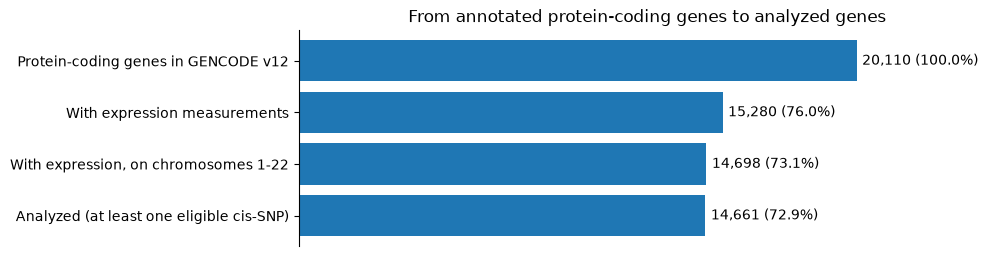

In [5]:
gene_flow = pd.Series({'Protein-coding genes in GENCODE v12': len(genes),
                       'With expression measurements': int(expressed.sum()),
                       'With expression, on chromosomes 1-22': int((expressed & autosomal).sum()),
                       'Analyzed (at least one eligible cis-SNP)': len(gene_hits)})
fig, ax = plt.subplots(figsize=(9, 2.8))
bars = ax.barh(gene_flow.index, gene_flow, color='C0')
ax.bar_label(bars, labels=[f'{v:,} ({v / len(genes):.1%})' for v in gene_flow], padding=4)
ax.invert_yaxis()
ax.set_xlim(0, gene_flow.max() * 1.25)
ax.set_title('From annotated protein-coding genes to analyzed genes')
ax.xaxis.set_visible(False)
ax.spines[['top', 'right', 'bottom']].set_visible(False)
fig.savefig(figures / '01_genes_kept_at_each_filtering_step.png', dpi=180, bbox_inches='tight')
plt.show()

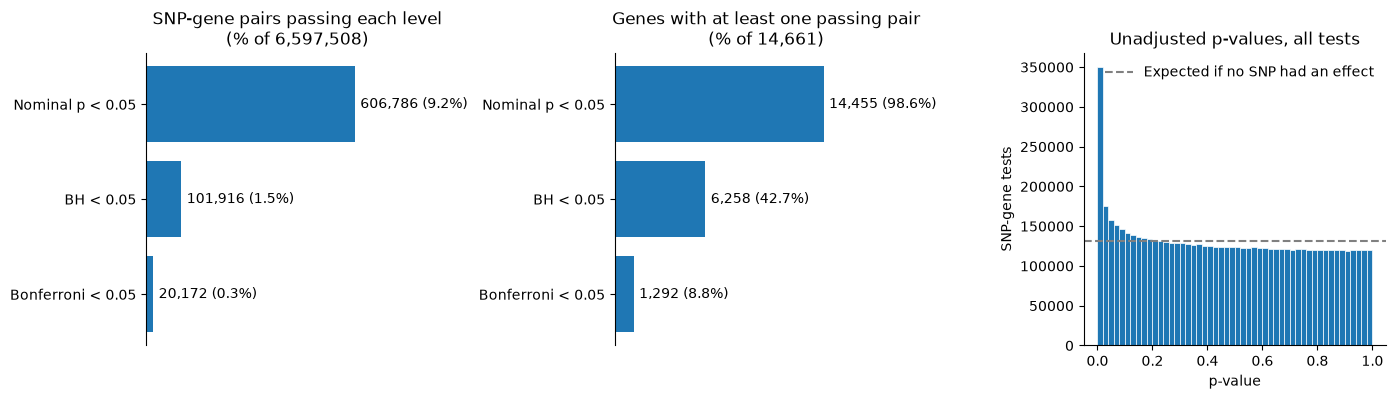

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8), gridspec_kw={'wspace': 0.55})
panels = [('SNP-gene pairs passing each level', number_of_tests, 'SNP-gene pairs'),
          ('Genes with at least one passing pair', len(gene_hits), 'Protein-coding genes')]
for ax, (title, total, key) in zip(axes, panels):
    bars = ax.barh(levels, correction_summary[key], color='C0')
    ax.bar_label(bars, labels=[f'{v:,} ({v / total:.1%})' for v in correction_summary[key]], padding=4)
    ax.invert_yaxis()
    ax.set_xlim(0, correction_summary[key].max() * 1.45)
    ax.set_title(f'{title}\n(% of {total:,})')
    ax.xaxis.set_visible(False)
    ax.spines['bottom'].set_visible(False)
axes[2].hist(associations['P'], bins=50, range=(0, 1), color='C0', edgecolor='white', linewidth=0.5)
axes[2].axhline(number_of_tests / 50, linestyle='--', color='gray', label='Expected if no SNP had an effect')
axes[2].set(title='Unadjusted p-values, all tests', xlabel='p-value', ylabel='SNP-gene tests')
axes[2].legend(frameon=False)
for ax in axes:
    ax.spines[['top', 'right']].set_visible(False)
fig.savefig(figures / '02_multiple_testing_results.png', dpi=180, bbox_inches='tight')
plt.show()

### Step 4: Main Results Tables

**Table A** has one row per SNP–gene association. **Table B** has one row per analyzed gene.
**Table C** has one row per chromosome; its `Genes_With_Significant_cis_eQTLs` column uses BH < 0.05.
Each is saved as a file, and only the first rows are shown here because Table A has millions of rows.

In [7]:
gene_columns = genes[['Gene_Symbol', 'Gene_Chr', 'Gene_Start', 'Gene_End']]
table_a = associations.join(gene_columns, on='Gene_ID').rename(columns={
    'SNP': 'SNP_ID', 'CHR': 'SNP_Chr', 'POS': 'SNP_Position', 'COUNTED': 'Counted_Allele',
    'BETA': 'Beta', 'P': 'P_Value'})
table_a = table_a[['Gene_ID', 'Gene_Symbol', 'Gene_Chr', 'Gene_Start', 'Gene_End', 'SNP_ID', 'SNP_Chr',
                   'SNP_Position', 'Counted_Allele', 'Beta', 'SE', 'P_Value', 'P_BH', 'P_Bonferroni', 'N']]
table_a.to_csv(part1 / 'table_A_genome_wide_cis_eqtl.tsv.gz', sep='\t', index=False,
               compression={'method': 'gzip', 'compresslevel': 1})

table_b = gene_columns.rename(columns={'Gene_Chr': 'Chr'}).join(gene_hits, how='inner')
table_b = table_b[['Gene_Symbol', 'Chr', 'SNPs_Tested', 'Nominal_Hits', 'BH_Hits', 'Bonferroni_Hits', 'Min_P_Value']]
table_b.index.name = 'Gene_ID'
table_b = table_b.sort_values('Min_P_Value')
table_b.to_csv(part1 / 'table_B_gene_summary.tsv', sep='\t')

table_b_chr = table_b['Chr'].astype(int)
table_c = pd.DataFrame({
    'Protein_Coding_Genes_Analyzed': table_b_chr.value_counts(),
    'SNP_Gene_Tests': table_a['Gene_Chr'].astype(int).value_counts(),
    'BH_Significant_Pairs': table_b.groupby(table_b_chr)['BH_Hits'].sum(),
    'Bonferroni_Significant_Pairs': table_b.groupby(table_b_chr)['Bonferroni_Hits'].sum(),
    'Genes_With_Significant_cis_eQTLs': table_b.loc[table_b['BH_Hits'].gt(0)].groupby(table_b_chr).size(),
}).reindex(chromosomes).fillna(0).astype(int)
table_c.index.name = 'Chromosome'
table_c.to_csv(part1 / 'table_C_chromosome_summary.tsv', sep='\t')

print('Table A:', table_a.shape)
display(table_a.sort_values('P_Value').head())
print('Table B:', table_b.shape)
display(table_b.head())
print('Table C:', table_c.shape)
display(table_c)

Table A: (6597508, 15)


,Gene_ID,Gene_Symbol,Gene_Chr,Gene_Start,Gene_End,SNP_ID,SNP_Chr,SNP_Position,Counted_Allele,Beta,SE,P_Value,P_BH,P_Bonferroni,N
4090475,ENSG00000197728.5,RPS26,12,56435637,56438116,rs10876864,12,56401085,A,-86.072626,2.049574,4.938813e-137,3.258386e-130,3.258386e-130,344
3619388,ENSG00000166796.7,LDHC,11,18433854,18473605,rs4757650,11,18415815,C,-1.259014,0.036095,1.112289e-114,2.446112e-108,7.338337e-108,344
3619394,ENSG00000166796.7,LDHC,11,18433854,18473605,rs11601413,11,18421683,C,-1.259014,0.036095,1.112289e-114,2.446112e-108,7.338337e-108,344
4090487,ENSG00000197728.5,RPS26,12,56435637,56438116,rs11171739,12,56470625,T,-82.330749,2.433421,3.627052e-111,5.982376e-105,2.392950e-104,344
1837540,ENSG00000164308.12,ERAP2,5,96211643,96255420,rs27290,5,96350088,A,-15.450085,0.463330,1.642397e-109,1.203970e-103,1.083573e-102,344


Table B: (14661, 7)


,Gene_Symbol,Chr,SNPs_Tested,Nominal_Hits,BH_Hits,Bonferroni_Hits,Min_P_Value
Gene_ID,,,,,,,
ENSG00000197728.5,RPS26,12,299,115,81,51,4.938813e-137
ENSG00000166796.7,LDHC,11,459,133,50,37,1.112289e-114
ENSG00000164308.12,ERAP2,5,529,213,134,72,1.642397e-109
ENSG00000182534.7,MXRA7,17,540,123,63,44,1.069619e-100
ENSG00000124587.9,PEX6,6,383,147,67,34,1.681247e-99


Table C: (22, 5)


,Protein_Coding_Genes_Analyzed,SNP_Gene_Tests,BH_Significant_Pairs,Bonferroni_Significant_Pairs,Genes_With_Significant_cis_eQTLs
Chromosome,,,,,
1,1566,668215,8881,1569,606
2,966,422393,6530,1165,408
3,841,382698,5890,924,339
4,521,240675,3910,751,227
5,670,314599,5078,889,288
6,799,376952,7979,1969,368
7,692,295955,5289,1024,295
8,535,248689,4256,900,220
9,600,283999,3898,706,273


### Checking the Analysis

Each check recomputes one requirement a different way, and the notebook stops with an error if any of
them fails. The full list of results is saved in `verification_checks.tsv`. Where the earlier weeks' local results exist, three checks also use them: people must match Week 2, chromosome 1 must reproduce Week 4's
regressions, and PARK7 must reproduce Week 3. One pair is always refit from the raw files with `numpy.polyfit`.

In [8]:
checks = {}

# Scope: protein-coding genes on all 22 autosomes.
checks['All 22 autosomes have results'] = sorted(table_a['Gene_Chr'].astype(int).unique()) == chromosomes
checks['Every analyzed gene is protein-coding in GENCODE'] = annotation.loc[table_b.index, 'Gene_Type'].eq('protein_coding').all()
checks['Every eligible gene is analyzed or has a recorded reason'] = len(table_b) + len(excluded) == len(genes)

# Windows and regression bookkeeping.
checks['Every SNP is on its gene\'s chromosome'] = (table_a['SNP_Chr'].astype(str) == table_a['Gene_Chr']).all()
checks['Every SNP is inside gene body +/- 500 kb'] = ((table_a['SNP_Position'] >= table_a['Gene_Start'] - 500000)
                                                       & (table_a['SNP_Position'] <= table_a['Gene_End'] + 500000)).all()
checks['No SNP-gene pair is tested twice'] = not table_a.duplicated(['Gene_ID', 'SNP_ID']).any()
checks['Every test uses all 344 people'] = table_a['N'].eq(len(ids)).all()
checks['All p-values, betas, and SEs are valid'] = (table_a['P_Value'].between(0, 1).all()
    and np.isfinite(table_a[['Beta', 'SE']]).all().all() and table_a['SE'].gt(0).all())

# Sample alignment: same people in the genotype files and the expression table.
fam_sets = [set(pd.read_csv(f'data/LDREF/1000G.EUR.{c}.fam', sep=r'\s+', header=None, dtype=str)[1]) for c in chromosomes]
checks['All matched people are in every genotype file'] = all(set(ids) <= f for f in fam_sets)
checks['All matched people are in the expression table'] = set(ids) <= set(expression.columns)

# Counted alleles come from the reference panel.
bim = pd.concat([pd.read_csv(f'data/LDREF/1000G.EUR.{c}.bim', sep=r'\s+', header=None, names=['Chr', 'SNP_ID', 'cM', 'Position', 'A1', 'A2'])
                 for c in chromosomes]).set_index('SNP_ID')
bim_for_tests = bim.reindex(table_a['SNP_ID'])
checks['SNP positions match the reference panel'] = (bim_for_tests['Position'].to_numpy() == table_a['SNP_Position'].to_numpy()).all()
checks['Counted alleles are alleles of that SNP'] = ((bim_for_tests['A1'].to_numpy() == table_a['Counted_Allele'].to_numpy())
                                                     | (bim_for_tests['A2'].to_numpy() == table_a['Counted_Allele'].to_numpy())).all()

# Corrections use the genome-wide family.
sorted_p = np.sort(table_a['P_Value'].to_numpy())
bh_passing = np.nonzero(sorted_p <= 0.05 * np.arange(1, number_of_tests + 1) / number_of_tests)[0]
checks['BH count matches a direct step-up calculation'] = bh_passing[-1] + 1 == table_a['P_BH'].lt(0.05).sum()
checks['Bonferroni count matches p < 0.05 / all tests'] = (table_a['P_Value'] < 0.05 / number_of_tests).sum() == table_a['P_Bonferroni'].lt(0.05).sum()

# Summary tables agree with Table A.
checks['Table B tests sum to Table A rows'] = table_b['SNPs_Tested'].sum() == len(table_a)
checks['Table B hits sum to Table A hits'] = (table_b['BH_Hits'].sum() == table_a['P_BH'].lt(0.05).sum()
                                              and table_b['Bonferroni_Hits'].sum() == table_a['P_Bonferroni'].lt(0.05).sum())
checks['Table C columns sum to Table A and Table B'] = (table_c['SNP_Gene_Tests'].sum() == len(table_a)
    and table_c['Protein_Coding_Genes_Analyzed'].sum() == len(table_b)
    and table_c['BH_Significant_Pairs'].sum() == table_a['P_BH'].lt(0.05).sum()
    and table_c['Bonferroni_Significant_Pairs'].sum() == table_a['P_Bonferroni'].lt(0.05).sum()
    and table_c['Genes_With_Significant_cis_eQTLs'].sum() == table_b['BH_Hits'].gt(0).sum())
saved_a = pd.read_csv(part1 / 'table_A_genome_wide_cis_eqtl.tsv.gz', sep='\t', usecols=['P_Value'])
checks['Saved Table A matches in-memory results'] = len(saved_a) == len(table_a) and np.allclose(saved_a['P_Value'], table_a['P_Value'], rtol=1e-12, atol=0)

week2_ids = Path('data/week2_results/matched_sample_ids.tsv')
if week2_ids.exists():
    checks['Matched people are the same as Week 2'] = pd.read_csv(week2_ids, sep='\t', dtype=str)['IID'].tolist() == ids

# Chromosome 1 reproduces Week 4, using Week 4's own all-gene output, when that local file exists.
if Path('data/week4_results/chr1_cis_eqtl.tsv.gz').exists():
    week4 = pd.read_csv('data/week4_results/chr1_cis_eqtl.tsv.gz', sep='\t', usecols=['Gene_ID', 'SNP', 'COUNTED', 'BETA', 'SE', 'P'])
    week4 = week4.loc[week4['Gene_ID'].isin(genes.index)]
    chr1 = table_a.loc[table_a['Gene_Chr'].eq('1')]
    matched = chr1.merge(week4, left_on=['Gene_ID', 'SNP_ID'], right_on=['Gene_ID', 'SNP'])
    print('Chromosome 1 protein-coding pairs here / Week 4 / matched:', len(chr1), len(week4), len(matched))
    print('Largest chromosome 1 beta and p-value difference from Week 4:',
          (matched['Beta'] - matched['BETA']).abs().max(), (matched['P_Value'] - matched['P']).abs().max())
    checks['Chromosome 1 pairs match Week 4 exactly'] = len(chr1) == len(week4) == len(matched) and matched['Counted_Allele'].eq(matched['COUNTED']).all()
    checks['Chromosome 1 betas and p-values match Week 4'] = (np.allclose(matched['Beta'], matched['BETA'], rtol=1e-9, atol=1e-12)
                                                             and np.allclose(matched['P_Value'], matched['P'], rtol=1e-6, atol=1e-300))

# PARK7 reproduces Week 3, when that local file exists.
if Path('data/week3_results/PARK7_cis_eqtl.tsv').exists():
    week3 = pd.read_csv('data/week3_results/PARK7_cis_eqtl.tsv', sep='\t')
    park7 = table_a.loc[table_a['Gene_ID'].eq('ENSG00000116288.8')].sort_values('P_Value').iloc[0]
    week3_lead = week3.sort_values('P_value').iloc[0]
    print('PARK7 lead SNP here:', park7['SNP_ID'], '| p =', park7['P_Value'])
    print('Week 3 lead SNP:', week3_lead['SNP_ID'], '| p =', week3_lead['P_value'])
    checks['PARK7 lead SNP and p-value match Week 3'] = park7['SNP_ID'] == week3_lead['SNP_ID'] and np.isclose(park7['P_Value'], week3_lead['P_value'], rtol=1e-9)

# One pair recomputed from the raw expression and genotype files.
spot = table_a.loc[table_a['Gene_Chr'].eq('22')].sort_values('P_Value').iloc[0]
raw_y = pd.read_csv(expression_path, sep='\t', usecols=['TargetID', *ids]).set_index('TargetID').loc[spot['Gene_ID'], ids].astype(float)
traw = pd.read_csv(part1 / 'chromosomes' / 'chr22.traw', sep=r'\s+')
row = traw.loc[traw['SNP'].eq(spot['SNP_ID'])].iloc[0]
spot_g = row[[column[i] for i in ids]].to_numpy(float)
spot_slope = np.polyfit(spot_g, raw_y.to_numpy(), 1)[0]
print('Spot check', spot['Gene_Symbol'], spot['SNP_ID'], '| Table A beta:', spot['Beta'], '| polyfit beta:', spot_slope)
checks['Refit from raw files matches Table A'] = np.isclose(spot_slope, spot['Beta'], rtol=1e-9) and row['COUNTED'] == spot['Counted_Allele']

verification = pd.Series(checks, name='Passed').to_frame()
verification.to_csv(part1 / 'verification_checks.tsv', sep='\t')
assert verification['Passed'].all()

Chromosome 1 protein-coding pairs here / Week 4 / matched: 668215 668215 668215
Largest chromosome 1 beta and p-value difference from Week 4: 0.0 2.6469779601696886e-23
PARK7 lead SNP here: rs11805932 | p = 0.0009957598850764
Week 3 lead SNP: rs11805932 | p = 0.0009957598850764
Spot check FAM118A rs104664 | Table A beta: -13.17109041383702 | polyfit beta: -13.171090413836911


### Step 5: Visualizing the Findings

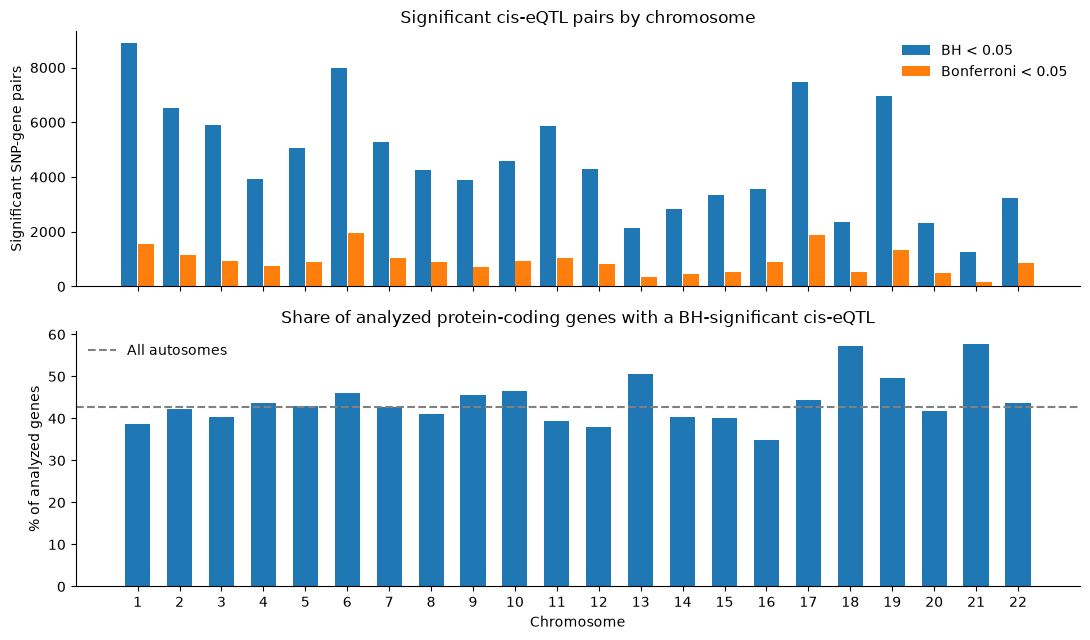

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
x = np.arange(len(table_c))
axes[0].bar(x - 0.2, table_c['BH_Significant_Pairs'], 0.38, color='C0', label='BH < 0.05')
axes[0].bar(x + 0.2, table_c['Bonferroni_Significant_Pairs'], 0.38, color='C1', label='Bonferroni < 0.05')
axes[0].set(ylabel='Significant SNP-gene pairs', title='Significant cis-eQTL pairs by chromosome')
axes[0].legend(frameon=False)
share = 100 * table_c['Genes_With_Significant_cis_eQTLs'] / table_c['Protein_Coding_Genes_Analyzed']
axes[1].bar(x, share, 0.6, color='C0')
axes[1].axhline(100 * table_b['BH_Hits'].gt(0).mean(), linestyle='--', color='gray', label='All autosomes')
axes[1].set(ylabel='% of analyzed genes', xlabel='Chromosome', title='Share of analyzed protein-coding genes with a BH-significant cis-eQTL')
axes[1].set_xticks(x, table_c.index)
axes[1].legend(frameon=False)
for ax in axes:
    ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(figures / '03_significant_cis_eqtls_by_chromosome.png', dpi=180)
plt.show()

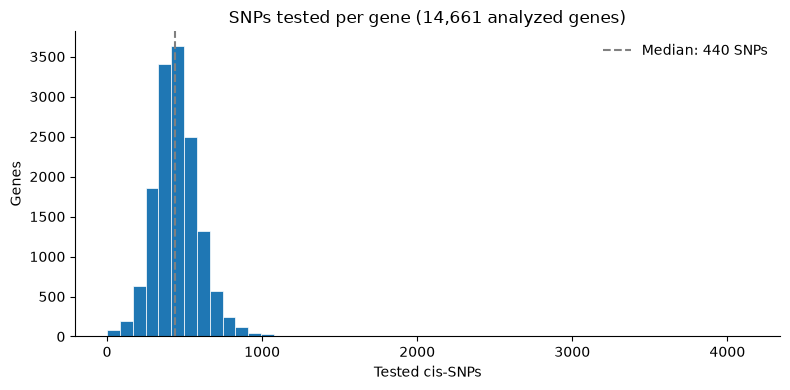

,SNPs tested per gene
count,14661.000000
mean,450.003956
std,153.332382
min,1.000000
25%,358.000000
50%,440.000000
75%,529.000000
max,4133.000000


,Gene_Symbol,Chr,SNPs_Tested,Gene_Length,Bonferroni_Hits
Gene_ID,,,,,
ENSG00000160183.8,TMPRSS3,21,4133,5379013,0
ENSG00000183117.10,CSMD1,8,3246,2059502,1
ENSG00000183486.7,MX2,21,2426,3012804,0
ENSG00000140945.10,CDH13,16,2055,1169796,0
ENSG00000186153.11,WWOX,16,1976,1113254,0


,Genes with no eligible cis-SNPs
Gene_Chr,
12,20
9,8
6,4
1,2
5,1
14,1
21,1


Widest SNP gap on chromosome 12: 6956462 to 10000986
Chromosome 12 genes with no cis-SNPs start between 7499281 and 9220260


In [10]:
median_snps = table_b['SNPs_Tested'].median()
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(table_b['SNPs_Tested'], bins=50, color='C0', edgecolor='white', linewidth=0.5)
ax.axvline(median_snps, linestyle='--', color='gray', label=f'Median: {median_snps:.0f} SNPs')
ax.set(title=f'SNPs tested per gene ({len(table_b):,} analyzed genes)', xlabel='Tested cis-SNPs', ylabel='Genes')
ax.legend(frameon=False)
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(figures / '04_snps_tested_per_gene.png', dpi=180)
plt.show()
display(table_b['SNPs_Tested'].describe().to_frame('SNPs tested per gene'))

longest = table_b.join(genes['Gene_End'].sub(genes['Gene_Start']).rename('Gene_Length'))
display(longest.nlargest(5, 'SNPs_Tested')[['Gene_Symbol', 'Chr', 'SNPs_Tested', 'Gene_Length', 'Bonferroni_Hits']])
no_snps = excluded.loc[excluded['Reason'].eq('No eligible cis-SNPs')]
display(no_snps['Gene_Chr'].value_counts().to_frame('Genes with no eligible cis-SNPs'))
chr12_positions = np.sort(pd.read_csv('data/LDREF/1000G.EUR.12.bim', sep=r'\s+', header=None, usecols=[3])[3].to_numpy())
widest = np.diff(chr12_positions).argmax()
print('Widest SNP gap on chromosome 12:', chr12_positions[widest], 'to', chr12_positions[widest + 1])
print('Chromosome 12 genes with no cis-SNPs start between', no_snps.loc[no_snps['Gene_Chr'].eq('12'), 'Gene_Start'].min(),
      'and', no_snps.loc[no_snps['Gene_Chr'].eq('12'), 'Gene_Start'].max())

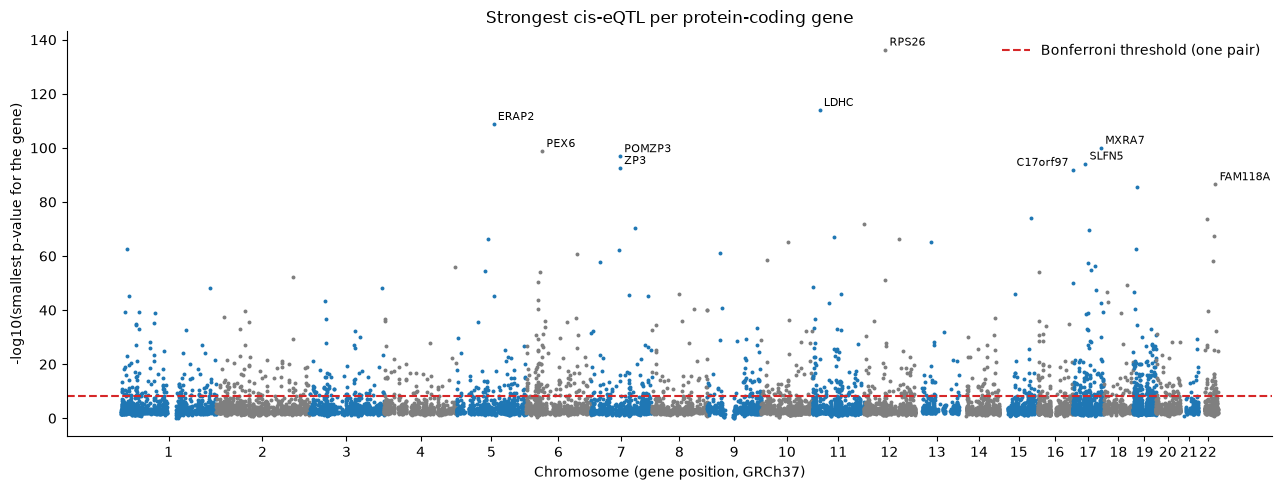

,Gene_Symbol,Gene_Chr,SNP_ID,Counted_Allele,Beta,P_Value,P_Bonferroni
4090475,RPS26,12,rs10876864,A,-86.072626,4.938813e-137,3.258386e-130
3619388,LDHC,11,rs4757650,C,-1.259014,1.112289e-114,7.338337e-108
1837540,ERAP2,5,rs27290,A,-15.450085,1.642397e-109,1.083573e-102
5500107,MXRA7,17,rs9303003,C,-2.856280,1.069619e-100,7.056822e-94
2210489,PEX6,6,rs10948059,C,-2.978059,1.681247e-99,1.109204e-92
2533559,POMZP3,7,rs17718122,A,-4.966675,1.372033e-97,9.051998e-91
5320521,SLFN5,17,rs883416,C,-6.530581,7.413177e-95,4.890849e-88
2532568,ZP3,7,rs17718122,A,-4.245106,3.240418e-93,2.137869e-86
5167983,C17orf97,17,rs11150882,G,-2.646672,1.601580e-92,1.056644e-85
6575922,FAM118A,22,rs104664,A,-13.171090,3.256798e-87,2.148675e-80


In [11]:
manhattan = table_b.join(genes[['Gene_Start', 'Gene_End']])
manhattan['Chr_Number'] = manhattan['Chr'].astype(int)
manhattan['Middle'] = (manhattan['Gene_Start'] + manhattan['Gene_End']) / 2
assert manhattan['Min_P_Value'].gt(0).all()
manhattan['Log_P'] = -np.log10(manhattan['Min_P_Value'])
lengths = manhattan.groupby('Chr_Number')['Middle'].max()
offsets = lengths.cumsum().shift(fill_value=0)
manhattan['Genome_Position'] = manhattan['Middle'] + manhattan['Chr_Number'].map(offsets)

fig, ax = plt.subplots(figsize=(13, 5))
for chrom, group in manhattan.groupby('Chr_Number'):
    ax.scatter(group['Genome_Position'], group['Log_P'], s=8, color='C0' if chrom % 2 else 'C7', linewidths=0)
ax.axhline(-np.log10(0.05 / number_of_tests), linestyle='--', color='C3', label='Bonferroni threshold (one pair)')
for _, top in manhattan.nsmallest(10, 'Min_P_Value').iterrows():
    label_left = top['Gene_Symbol'] == 'C17orf97'  # keeps this label off its chromosome 17 neighbors
    ax.annotate(top['Gene_Symbol'], (top['Genome_Position'], top['Log_P']), xytext=(-3 if label_left else 3, 3),
                textcoords='offset points', ha='right' if label_left else 'left', fontsize=8)
ax.set_xticks(offsets + lengths / 2, chromosomes)
ax.set(xlabel='Chromosome (gene position, GRCh37)', ylabel='-log10(smallest p-value for the gene)',
       title='Strongest cis-eQTL per protein-coding gene')
ax.legend(frameon=False)
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(figures / '05_manhattan_strongest_cis_eqtl_per_gene.png', dpi=180)
plt.show()

lead_snps = table_a.sort_values('P_Value').drop_duplicates('Gene_ID')
top_genes = lead_snps.head(15)[['Gene_Symbol', 'Gene_Chr', 'SNP_ID', 'Counted_Allele', 'Beta', 'P_Value', 'P_Bonferroni']]
display(top_genes)

### A Closer Look at the Strongest Signal

This looks at the gene with the smallest p-value in the genome. The left panel shows why one gene produces many
significant pairs: nearby SNPs in LD carry nearly the same signal. The right panel shows the lead
SNP's effect in the people themselves.

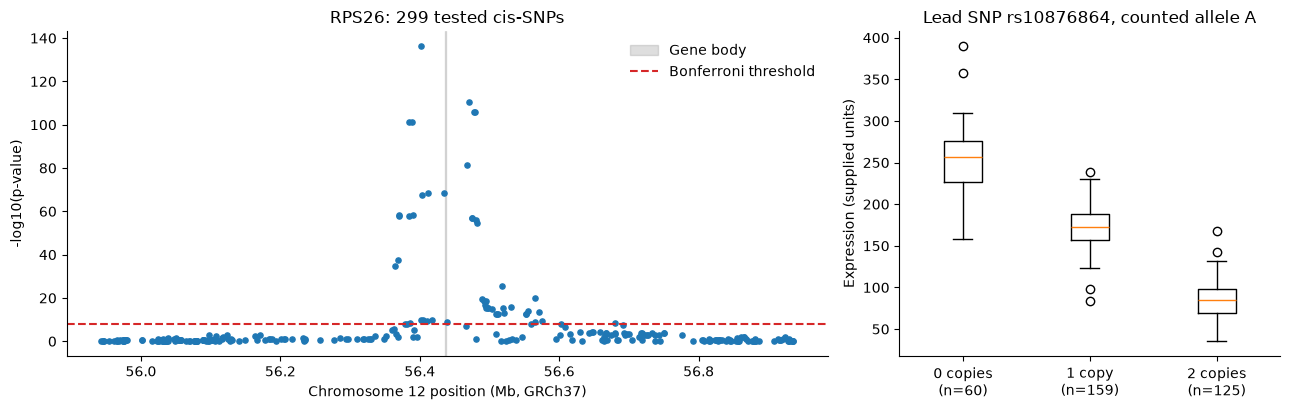

Median expression by copies: [257.2, 172.7, 85.3]
Lead SNP distance from gene start: 34552 bp
Bonferroni-significant SNPs for this gene: 51


In [12]:
top_gene = table_b.index[0]
locus = table_a.loc[table_a['Gene_ID'].eq(top_gene)].sort_values('SNP_Position')
top_snp = locus.loc[locus['P_Value'].idxmin()]
top_traw = pd.read_csv(part1 / 'chromosomes' / f"chr{top_snp['Gene_Chr']}.traw", sep=r'\s+')
top_dosage = top_traw.loc[top_traw['SNP'].eq(top_snp['SNP_ID']), [column[i] for i in ids]].iloc[0].to_numpy(float)
top_expression = expression.loc[top_gene, ids].to_numpy(float)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={'width_ratios': [2, 1]})
axes[0].axvspan(top_snp['Gene_Start'] / 1e6, top_snp['Gene_End'] / 1e6, color='C7', alpha=0.25, label='Gene body')
axes[0].scatter(locus['SNP_Position'] / 1e6, -np.log10(locus['P_Value']), s=14, color='C0')
axes[0].axhline(-np.log10(0.05 / number_of_tests), linestyle='--', color='C3', label='Bonferroni threshold')
axes[0].set(xlabel=f"Chromosome {top_snp['Gene_Chr']} position (Mb, GRCh37)", ylabel='-log10(p-value)',
            title=f"{top_snp['Gene_Symbol']}: {len(locus)} tested cis-SNPs")
axes[0].legend(frameon=False)
copies = [0, 1, 2]
groups = [top_expression[top_dosage == k] for k in copies]
axes[1].boxplot(groups, tick_labels=[f"{k} {'copy' if k == 1 else 'copies'}\n(n={len(g)})" for k, g in zip(copies, groups)])
axes[1].set(ylabel='Expression (supplied units)', title=f"Lead SNP {top_snp['SNP_ID']}, counted allele {top_snp['Counted_Allele']}")
for ax in axes:
    ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(figures / f"06_{top_snp['Gene_Symbol']}_association_and_expression_by_genotype.png", dpi=180)
plt.show()
print('Median expression by copies:', [round(float(np.median(g)), 1) for g in groups])
print('Lead SNP distance from gene start:', int(top_snp['Gene_Start'] - top_snp['SNP_Position']), 'bp')
print('Bonferroni-significant SNPs for this gene:', int(locus['P_Bonferroni'].lt(0.05).sum()))

### LocusZoom Plot of the Strongest cis-eQTL

A LocusZoom plot shows the whole cis-window for one gene, with three tracks on the same position axis:

- **Association:** each point is one tested SNP. Its color shows its LD (r²) with the lead SNP, the purple
  diamond, measured in the same 344 people. Red points are largely inherited together with the lead SNP.
- **Recombination rate:** calculated between neighboring SNPs from the genetic-map column of the `.bim` file.
  LD tends to break down across recombination peaks.
- **Genes:** protein-coding genes in the window, with exons as thick bars and arrows showing direction. The
  mapped gene is in red.

The plot is drawn in matplotlib using LocusZoom's layout and color scheme, so it needs no extra software.

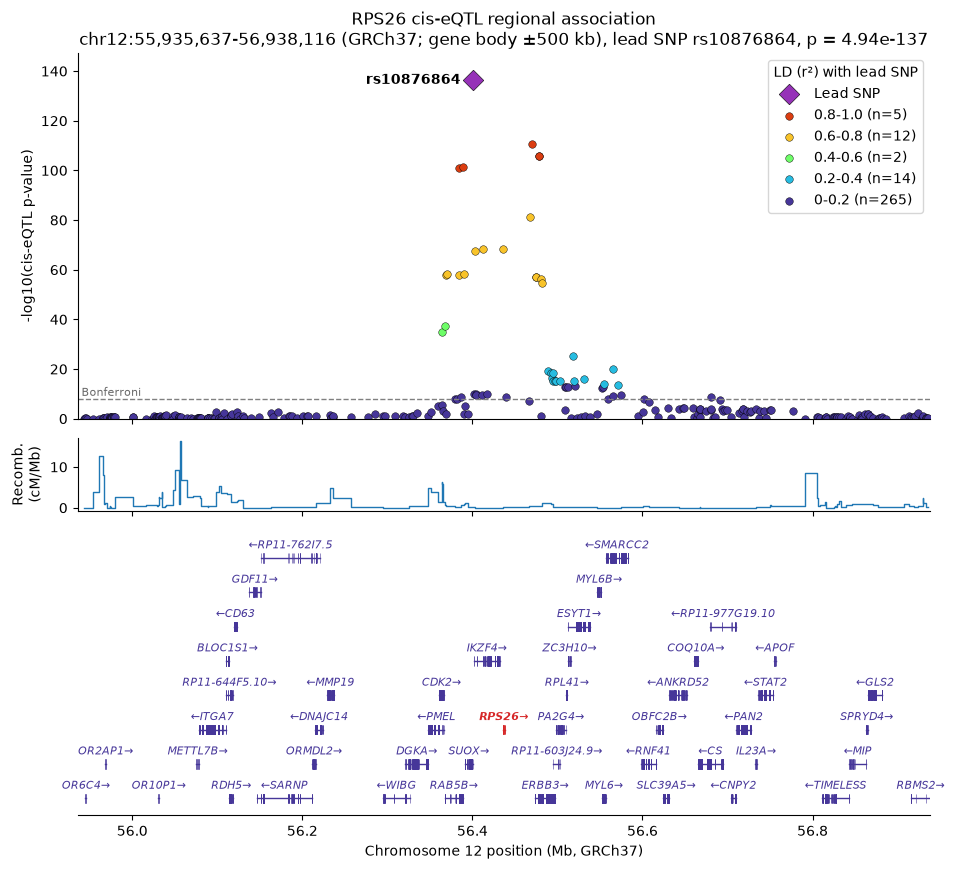

,All tested SNPs,Bonferroni-significant SNPs
r² > 0.8,6,6
r² > 0.5,18,18
r² > 0.2,34,34


Tested SNPs: 299 | Bonferroni-significant SNPs: 51


In [13]:
ld_bins = [(0.8, 1.01, '#DB3D11', '0.8-1.0'), (0.6, 0.8, '#F8C32A', '0.6-0.8'), (0.4, 0.6, '#6EFE68', '0.4-0.6'),
           (0.2, 0.4, '#26BCE1', '0.2-0.4'), (0, 0.2, '#463699', '0-0.2')]

def locus_zoom(gene_id, output_path):
    '''LocusZoom-style plot: association colored by LD with the lead SNP, recombination rate, and nearby genes.'''
    locus = table_a.loc[table_a['Gene_ID'].eq(gene_id)].sort_values('SNP_Position').copy()
    lead = locus.loc[locus['P_Value'].idxmin()]
    chrom, start, end = lead['Gene_Chr'], lead['Gene_Start'] - 500000, lead['Gene_End'] + 500000

    # r2 with the lead SNP, among the same 344 people used in the regressions.
    traw = pd.read_csv(part1 / 'chromosomes' / f'chr{chrom}.traw', sep=r'\s+').set_index('SNP')
    dosages = traw.loc[locus['SNP_ID'], [column[i] for i in ids]].to_numpy(float)
    locus['LD_R2'] = np.corrcoef(dosages)[list(locus['SNP_ID']).index(lead['SNP_ID'])] ** 2
    locus['Log_P'] = -np.log10(locus['P_Value'])

    # Recombination rate between neighboring SNPs, from the genetic-map column of the .bim file.
    bim_map = pd.read_csv(f'data/LDREF/1000G.EUR.{chrom}.bim', sep=r'\s+', header=None, usecols=[2, 3], names=['cM', 'Position'])
    bim_map = bim_map.loc[bim_map['Position'].between(start, end)].sort_values('Position')
    recombination = bim_map['cM'].diff() / bim_map['Position'].diff() * 1e6

    # Exons of the protein-coding genes overlapping the window.
    nearby = genes.loc[genes['Gene_Chr'].eq(chrom) & (genes['Gene_End'] >= start) & (genes['Gene_Start'] <= end)].sort_values('Gene_Start')
    annotation_rows = pd.read_csv(gtf_path, sep='\t', comment='#', header=None, usecols=[0, 2, 3, 4, 6, 8])
    exons = annotation_rows.loc[annotation_rows[0].eq(f'chr{chrom}') & annotation_rows[2].eq('exon')
                                & (annotation_rows[4] >= start) & (annotation_rows[3] <= end)].copy()
    exons['Gene_ID'] = exons[8].str.extract(r'gene_id "([^"]+)"')[0]
    exons = exons.loc[exons['Gene_ID'].isin(nearby.index)]
    strands = exons.groupby('Gene_ID')[6].first()

    # Put genes on rows so that bars and labels do not overlap.
    character_width = (end - start) * 0.0095
    row_ends, rows = [], {}
    for gene, record in nearby.iterrows():
        left, right = max(record['Gene_Start'], start), min(record['Gene_End'], end)
        middle = (left + right) / 2
        half_label = (len(record['Gene_Symbol']) + 2) * character_width / 2
        needed_left, needed_right = min(left, middle - half_label), max(right, middle + half_label)
        row = next((r for r, row_end in enumerate(row_ends) if row_end < needed_left), len(row_ends))
        row_ends[row:row + 1] = [needed_right]
        rows[gene] = row

    fig, axes = plt.subplots(3, 1, figsize=(11, 7.5 + 0.3 * len(row_ends)), sharex=True,
                             gridspec_kw={'height_ratios': [5, 1, 0.45 * len(row_ends) + 0.3], 'hspace': 0.08})
    association, rate, track = axes

    for low, high, color, label in reversed(ld_bins):
        group = locus.loc[locus['LD_R2'].ge(low) & locus['LD_R2'].lt(high) & locus['SNP_ID'].ne(lead['SNP_ID'])]
        association.scatter(group['SNP_Position'] / 1e6, group['Log_P'], s=30, color=color, edgecolor='black',
                            linewidth=0.3, label=f'{label} (n={len(group)})')
    association.scatter(lead['SNP_Position'] / 1e6, -np.log10(lead['P_Value']), s=110, marker='D', color='#9632B8',
                        edgecolor='black', linewidth=0.4, zorder=3, label='Lead SNP')
    association.annotate(lead['SNP_ID'], (lead['SNP_Position'] / 1e6, -np.log10(lead['P_Value'])), xytext=(-9, 0),
                         textcoords='offset points', ha='right', va='center', fontweight='bold')
    association.axhline(-np.log10(0.05 / number_of_tests), linestyle='--', color='gray', linewidth=1)
    association.text(start / 1e6, -np.log10(0.05 / number_of_tests), ' Bonferroni', va='bottom', color='dimgray', fontsize=8)
    handles, labels = association.get_legend_handles_labels()
    order = [labels.index('Lead SNP')] + [i for i, name in enumerate(labels) if name != 'Lead SNP'][::-1]
    association.legend([handles[i] for i in order], [labels[i] for i in order], title='LD (r²) with lead SNP', loc='upper right', frameon=True)
    association.set(ylabel='-log10(cis-eQTL p-value)', ylim=(0, locus['Log_P'].max() * 1.08),
                    title=f"{lead['Gene_Symbol']} cis-eQTL regional association\n"
                          f"chr{chrom}:{start:,}-{end:,} (GRCh37; gene body ±500 kb), lead SNP {lead['SNP_ID']}, p = {lead['P_Value']:.2e}")

    rate.step(bim_map['Position'] / 1e6, recombination, where='pre', color='C0', linewidth=1)
    rate.set_ylabel('Recomb.\n(cM/Mb)')

    for gene, record in nearby.iterrows():
        row = rows[gene]
        target = gene == gene_id
        color = 'C3' if target else '#463699'
        left, right = max(record['Gene_Start'], start), min(record['Gene_End'], end)
        track.plot([left / 1e6, right / 1e6], [row, row], color=color, linewidth=1)
        for _, exon in exons.loc[exons['Gene_ID'].eq(gene)].iterrows():
            track.fill_between([exon[3] / 1e6, exon[4] / 1e6], row - 0.14, row + 0.14, color=color, linewidth=0.4)
        symbol = record['Gene_Symbol']
        arrow = f'{symbol}→' if strands.get(gene) == '+' else f'←{symbol}'
        track.text((left + right) / 2e6, row + 0.2, arrow, ha='center', va='bottom', fontsize=8, style='italic',
                   color=color, fontweight='bold' if target else 'normal')
    track.set_ylim(-0.5, len(row_ends) - 0.2)
    track.yaxis.set_visible(False)
    track.set(xlim=(start / 1e6, end / 1e6), xlabel=f'Chromosome {chrom} position (Mb, GRCh37)')
    track.spines['left'].set_visible(False)
    for ax in axes:
        ax.spines[['top', 'right']].set_visible(False)
    fig.savefig(output_path, dpi=180, bbox_inches='tight')
    plt.show()
    return locus

zoom_locus = locus_zoom(top_gene, figures / f'07_{table_b.loc[top_gene, "Gene_Symbol"]}_locuszoom.png')
zoom_significant = zoom_locus['P_Bonferroni'].lt(0.05)
ld_counts = pd.DataFrame({
    'All tested SNPs': [int((zoom_locus['LD_R2'] > r).sum()) for r in (0.8, 0.5, 0.2)],
    'Bonferroni-significant SNPs': [int(((zoom_locus['LD_R2'] > r) & zoom_significant).sum()) for r in (0.8, 0.5, 0.2)],
}, index=['r² > 0.8', 'r² > 0.5', 'r² > 0.2'])
display(ld_counts)
print('Tested SNPs:', len(zoom_locus), '| Bonferroni-significant SNPs:', int(zoom_significant.sum()))

### Are Rare SNPs or Outliers Driving the Hits?

There is no MAF filter and expression values are heavy-tailed, so a SNP carried by a few people could
look significant because one of them has an unusual expression value. This check does **not** change
any result above; it shows how much to trust them.

The first table groups tests by minor allele count (MAC), the number of copies of the rarer allele among
the 344 people. The second refits the 15 strongest genes with **Spearman correlation**, which uses ranks,
so one extreme value has limited influence.

In [14]:
minor_counts = []
for chrom in chromosomes:
    traw = pd.read_csv(part1 / 'chromosomes' / f'chr{chrom}.traw', sep=r'\s+')
    counted = traw[[column[i] for i in ids]].sum(axis=1)
    minor_counts.append(pd.Series(np.minimum(counted, 2 * len(ids) - counted).to_numpy(), index=traw['SNP']))
minor_counts = pd.concat(minor_counts)

mac = pd.cut(table_a['SNP_ID'].map(minor_counts), [0, 1, 4, 9, np.inf], labels=['1', '2-4', '5-9', '10 or more'])
mac_summary = pd.DataFrame({
    'Tests': table_a.groupby(mac, observed=True).size(),
    'Nominal_Rate': table_a['P_Value'].lt(0.05).groupby(mac, observed=True).mean().round(4),
    'BH_Pairs': table_a['P_BH'].lt(0.05).groupby(mac, observed=True).sum(),
    'Bonferroni_Pairs': table_a['P_Bonferroni'].lt(0.05).groupby(mac, observed=True).sum(),
})
mac_summary.index.name = 'Minor_Allele_Count'
mac_summary.to_csv(part1 / 'minor_allele_count_summary.tsv', sep='\t')
display(mac_summary)

common = mac.eq('10 or more').to_numpy()
for name, column_name in [('BH', 'P_BH'), ('Bonferroni', 'P_Bonferroni')]:
    passing = table_a[column_name].lt(0.05).to_numpy()
    any_hit = table_a.loc[passing, 'Gene_ID'].nunique()
    common_hit = table_a.loc[passing & common, 'Gene_ID'].nunique()
    print(f'{name}: {any_hit} genes have a hit; {any_hit - common_hit} have hits only from SNPs with MAC below 10')
    print(f'{name}: median significant SNPs per significant gene:', table_a.loc[passing].groupby('Gene_ID').size().median())

rows = []
for _, lead in lead_snps.head(15).iterrows():
    traw = pd.read_csv(part1 / 'chromosomes' / f"chr{lead['Gene_Chr']}.traw", sep=r'\s+')
    dosage = traw.loc[traw['SNP'].eq(lead['SNP_ID']), [column[i] for i in ids]].iloc[0].to_numpy(float)
    y = expression.loc[lead['Gene_ID'], ids].to_numpy(float)
    rows.append({'Gene_Symbol': lead['Gene_Symbol'], 'SNP_ID': lead['SNP_ID'], 'MAC': int(minor_counts[lead['SNP_ID']]),
                 'Regression_P': lead['P_Value'], 'Spearman_P': spearmanr(dosage, y).pvalue,
                 'Largest_Expression_Z': (y.max() - y.mean()) / y.std()})
robustness = pd.DataFrame(rows)
robustness['Spearman_Passes_Bonferroni_Cutoff'] = robustness['Spearman_P'] < 0.05 / number_of_tests
robustness.to_csv(part1 / 'top_gene_robustness.tsv', sep='\t', index=False)
display(robustness)

,Tests,Nominal_Rate,BH_Pairs,Bonferroni_Pairs
Minor_Allele_Count,,,,
1,2462,0.0439,15,5
2-4,40051,0.0566,346,63
5-9,114712,0.0586,688,59
10 or more,6440283,0.0928,100867,20045


BH: 6258 genes have a hit; 254 have hits only from SNPs with MAC below 10
BH: median significant SNPs per significant gene: 6.0
Bonferroni: 1292 genes have a hit; 59 have hits only from SNPs with MAC below 10
Bonferroni: median significant SNPs per significant gene: 9.0


,Gene_Symbol,SNP_ID,MAC,Regression_P,Spearman_P,Largest_Expression_Z,Spearman_Passes_Bonferroni_Cutoff
0,RPS26,rs10876864,279,4.938813e-137,2.429207e-128,3.525443,True
1,LDHC,rs4757650,75,1.112289e-114,2.038932e-48,5.519980,True
2,ERAP2,rs27290,289,1.642397e-109,8.166660e-99,2.683058,True
3,MXRA7,rs9303003,65,1.069619e-100,1.003173e-44,4.492148,True
4,PEX6,rs10948059,338,1.681247e-99,3.959112e-102,2.988833,True
5,POMZP3,rs17718122,195,1.372033e-97,2.096225e-101,4.096993,True
6,SLFN5,rs883416,343,7.413177e-95,8.331263e-91,2.738708,True
7,ZP3,rs17718122,195,3.240418e-93,8.098006e-92,4.059302,True
8,C17orf97,rs11150882,163,1.601580e-92,1.174211e-97,4.447443,True
9,FAM118A,rs104664,89,3.256798e-87,4.658514e-51,4.540184,True


### Results and Interpretation

The findings from this notebook and their interpretation are in [quarter1_part1_results.md](../quarter1_part1_results.md).